### Student Marks Prediction using Linear Regression

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('StudentMarksDataset.csv')
df.head()

,Std_RollNo,Std_Name,Std_Branch,Std_Course,Std_StudyHours,Std_Marks
0,240415,Tanya Gautam,MC,B.Sc 1st year,6.83,78.50
1,240416,Udit Sagan,MC,B.Sc 1st year,6.56,76.74
2,240417,Kratika Sharma,PM,B.Sc 1st year,NaN,78.68
3,240418,Rakesh Kumar,PM,B.Sc 1st year,5.67,71.82
4,240419,Ritika Katara,PM,B.Sc 1st year,8.67,84.19


In [4]:
df.corr(numeric_only=True)

df_new = df.drop(columns=['Std_RollNo','Std_Name','Std_Branch','Std_Course'])
df_new.head()

df_new['Std_StudyHours'] = df_new['Std_StudyHours'].fillna(df_new['Std_StudyHours'].mean())

In [5]:
df_new.isnull().sum()

Std_StudyHours    0
Std_Marks         0
dtype: int64

In [6]:
#Separate the independent and dependent features

X = df_new[['Std_StudyHours']]
y = df_new['Std_Marks']

In [7]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=45)

In [8]:
#standardization

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_train


array([[ 1.24988875],
       [-1.48314814],
       [ 1.50787454],
       [-1.60407898],
       [-1.16066591],
       [-0.95105246],
       [ 1.4595022 ],
       [-0.05136839],
       [-0.14484689],
       [ 0.71779307],
       [ 0.20182151],
       [ 0.71779307],
       [-1.57183075],
       [-1.02361096],
       [ 0.37112468],
       [ 1.2418267 ],
       [ 0.19375945],
       [ 1.33857136],
       [ 0.04864245],
       [ 0.50817962],
       [ 0.64523457],
       [ 0.64523457],
       [ 1.39500575],
       [-0.56407379],
       [-0.66081846],
       [ 0.91934447],
       [-0.54794968],
       [ 1.09670969],
       [ 0.99996502],
       [ 0.86291008],
       [ 0.9677168 ],
       [-0.05136839],
       [-0.40283267],
       [-1.34609319],
       [ 0.81453774],
       [-1.15260386],
       [ 0.88709624],
       [ 0.99996502],
       [ 1.42725398],
       [-1.54764459],
       [ 0.10507684],
       [ 0.20182151],
       [ 1.33050931],
       [-1.54764459],
       [-0.37058445],
       [-1

In [9]:
X_test = scaler.transform(X_test)
X_test

array([[-0.70919079],
       [-0.57213584],
       [-1.43477581],
       [-1.34609319],
       [ 0.72585513],
       [ 0.67748279],
       [-1.46702403],
       [ 1.03221325],
       [-1.12035563],
       [ 0.83066185],
       [-0.44314295],
       [ 1.54012276],
       [-1.48314814],
       [ 1.3869437 ],
       [-0.57213584],
       [ 1.29019903],
       [-0.11259867],
       [-0.58825996],
       [ 0.95965475],
       [-1.02361096],
       [-1.04779713],
       [ 0.23406973],
       [ 0.03251834],
       [-0.70919079],
       [-1.22516236],
       [-0.37864651],
       [ 0.13732506],
       [-1.02361096],
       [-0.44314295],
       [ 0.10507684],
       [-0.91880424],
       [-0.18515717],
       [-1.64438926],
       [-0.57213584],
       [-0.2335295 ],
       [-0.32221212],
       [ 1.46756426],
       [ 1.0402753 ],
       [ 1.29826109],
       [-0.90268013],
       [-1.49927225],
       [-1.34609319],
       [ 1.33050931],
       [ 0.9677168 ],
       [-1.34609319],
       [-1

In [10]:
#Apply Linear Regession
from sklearn.linear_model import LinearRegression

regression = LinearRegression()

regression.fit(X_train,y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[4.73]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,78.23
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[12.25]


In [11]:
print(regression.coef_)

[4.73397906]


In [12]:
print(regression.intercept_)

78.23026666666667


Text(0, 0.5, 'Marks')

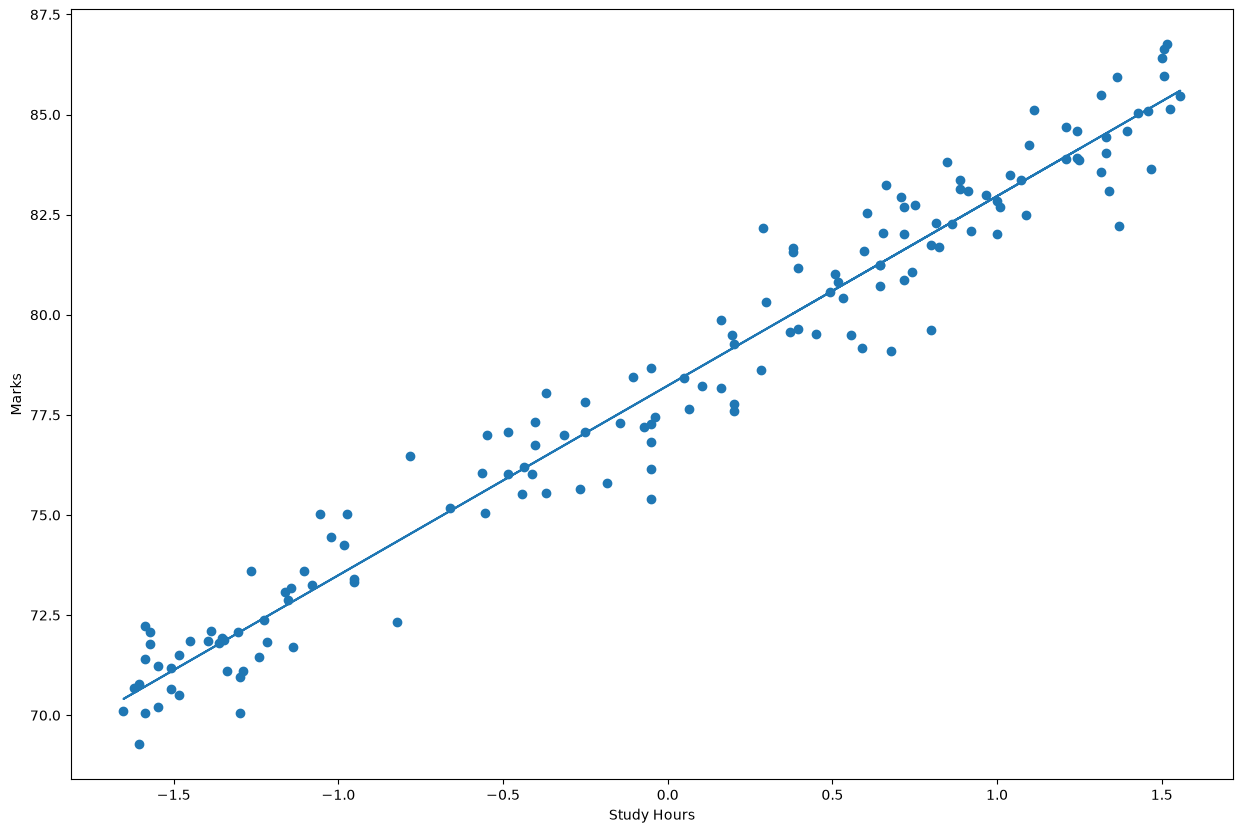

In [13]:
plt.figure(figsize=(15,10))
plt.scatter(X_train,y_train)
plt.plot(X_train,regression.predict(X_train))
plt.xlabel('Study Hours')
plt.ylabel('Marks')

In [14]:
y_pred = regression.predict(X_test)
y_pred

array([74.87297231, 75.52178756, 71.43806804, 71.85788968, 81.66644965,
       81.43745603, 71.28540563, 83.11674256, 72.92652656, 82.16260249,
       76.13243721, 85.52117555, 71.20907442, 84.79602909, 75.52178756,
       84.33804186, 77.69722694, 75.44545636, 82.77325214, 73.3845138 ,
       73.27001699, 79.33834786, 78.38420779, 74.87297231, 72.43037372,
       76.43776204, 78.88036063, 73.3845138 , 76.13243721, 78.72769822,
       73.88066663, 77.35373651, 70.44576236, 75.52178756, 77.12474289,
       76.70492126, 85.17768512, 83.15490817, 84.37620746, 73.95699784,
       71.13274322, 71.85788968, 84.52886987, 82.81141774, 71.85788968,
       71.89605528, 83.07857696, 79.8345007 , 78.99485744, 74.22415706])

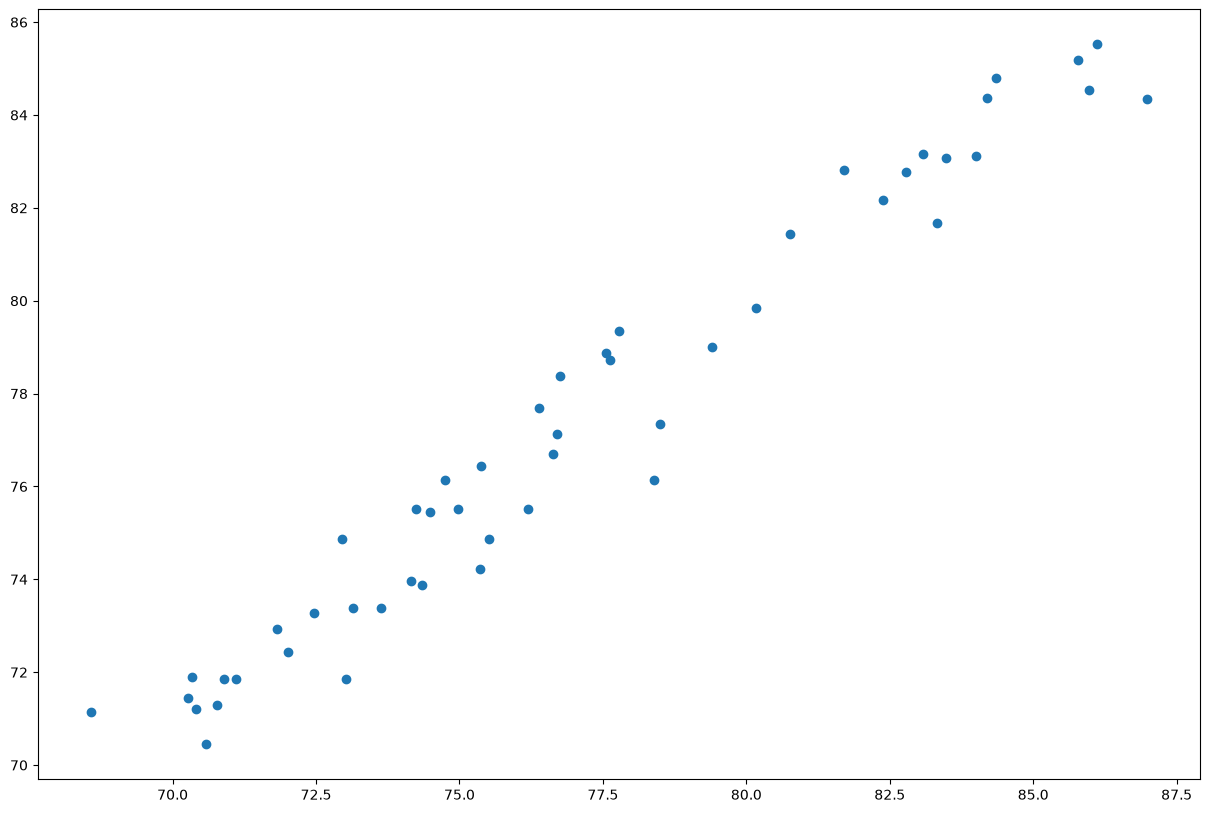

In [15]:
plt.figure(figsize=(15,10))
plt.scatter(y_test,y_pred)

In [16]:
#Performance matrix
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mse)


In [17]:
print(mse)
print(mae)
print(rmse)

1.2094636589228889
0.9052121762474326
1.0997561815797576


In [18]:
from sklearn.metrics import r2_score

score = r2_score(y_test,y_pred)

In [19]:
print(score)
print(y_test)
print(y_pred)

0.9523206096523211
45     72.96
72     74.97
40     70.27
58     70.90
25     83.33
13     80.76
153    70.78
80     84.00
3      71.82
44     82.38
134    78.39
149    86.12
173    70.40
33     84.35
62     76.19
182    86.99
112    76.38
129    74.49
69     82.79
190    73.14
133    72.46
172    77.78
35     76.76
157    75.52
187    72.01
10     75.37
104    77.55
177    73.64
26     74.75
171    77.63
147    74.34
0      78.50
109    70.58
194    74.24
151    76.70
82     76.63
64     85.78
169    83.08
4      84.19
28     74.15
97     68.57
174    73.02
138    85.98
67     81.70
175    71.11
116    70.34
135    83.48
29     80.17
61     79.41
83     75.36
Name: Std_Marks, dtype: float64
[74.87297231 75.52178756 71.43806804 71.85788968 81.66644965 81.43745603
 71.28540563 83.11674256 72.92652656 82.16260249 76.13243721 85.52117555
 71.20907442 84.79602909 75.52178756 84.33804186 77.69722694 75.44545636
 82.77325214 73.3845138  73.27001699 79.33834786 78.38420779 74.87297231
 72.430

In [20]:
1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1)

0.9513272890200778

In [21]:
new_data = pd.DataFrame({'Std_StudyHours': [7.34]}) 
new_pred = regression.predict(scaler.transform(new_data))
print(new_pred)

[79.30018226]


In [22]:
new_data2 = pd.DataFrame({'Std_StudyHours': [5.64]})   
new_pred2 = regression.predict(scaler.transform(new_data2))
print(new_pred2)

[72.81202975]


### Using OLS method

In [23]:
import statsmodels.api as sm

In [24]:
sm.add_constant(X_train)
model = sm.OLS(y_train,X_train).fit()


In [25]:
prediction = model.predict(X_test)
print(prediction)

[-3.35729435 -2.7084791  -6.79219862 -6.37237699  3.43618298  3.20718936
 -6.94486104  4.8864759  -5.30374011  3.93233582 -2.09782945  7.29090889
 -7.02119224  6.56576243 -2.7084791   6.10777519 -0.53303973 -2.78481031
  4.54298547 -4.84575287 -4.96024968  1.1080812   0.15394112 -3.35729435
 -5.79989295 -1.79250463  0.65009396 -4.84575287 -2.09782945  0.49743155
 -4.34960003 -0.87653016 -7.7845043  -2.7084791  -1.10552378 -1.52534541
  6.94741846  4.9246415   6.14594079 -4.27326883 -7.09752345 -6.37237699
  6.29860321  4.58115107 -6.37237699 -6.33421139  4.84831029  1.60423404
  0.76459077 -4.0061096 ]


In [26]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:              Std_Marks   R-squared (uncentered):                   0.004
Model:                            OLS   Adj. R-squared (uncentered):             -0.003
Method:                 Least Squares   F-statistic:                             0.5455
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                       0.461
Time:                        20:09:35   Log-Likelihood:                         -866.80
No. Observations:                 150   AIC:                                      1736.
Df Residuals:                     149   BIC:                                      1739.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

### Conclusion       
                                                                        
    ### 1. Model Performance Summary            
    R2 Score: 0.9984 (99.84%) -        
  Captures nearly all variance in property      
  prices across the test set.                   
    Adjusted R2: 0.9983 — Accurately   
  reflects model quality while accounting for   
  multiple predictors.                          
    * **Mean Absolute Error (MAE): $8,152.90**  
    * **Root Mean Squared Error (RMSE): $10,183.
  28** — On homes priced between $100,000 and   
  $1,200,000+, this corresponds to an average   
  prediction error of just **~1%**.             
                                                
    ### 2. Key Statistical Insights & Feature   
  Selection                                     
    * **Why Multivariate Analysis Outperformed  
  Univariate Correlation**:                     
      * In isolation, `Num_Bedrooms` ($r = 0.   
  014$) and `Num_Bathrooms` ($r = -0.001$)      
  appeared uncorrelated because `Square_Footage`
  dominates overall price scale.                
      * However, multiple regression revealed   
  both are **highly statistically significant   
  ($p < 0.001$)**:                              
        * Each additional bedroom adds **+$10,  
  160** to property value.                      
        * Each additional bathroom adds **+$8,  
  250** to property value.                      
    * **Data-Driven Feature Pruning**:          
      * `Neighborhood_Quality` showed a p-value 
  of **0.454 ($p > 0.05$)**, indicating random  
  noise. Pruning this feature reduced model     
  complexity and improved the Akaike Information
  Criterion (AIC).                              
    * **Strongest Drivers**:                    
      1. `Square_Footage` (~$199.75 / sq.ft.)   
      2. `Lot_Size` (~$14,930 / unit)           
      3. `Num_Bedrooms` & `Num_Bathrooms`       
                                                
    ### 3. Engineering & Modeling Highlights    
    1. **Zero Data Leakage**: Fitted feature    
  scaling exclusively on training partitions.   
    2. **Dual Verification**: Validated machine 
  learning predictions using `scikit-learn` and 
  corroborated feature coefficients/p-values via
  `statsmodels.OLS`.    